# 04. Exploratory crime IV: residential versus business/community burglary

This extension changes the target crime to **residential burglary**, instrumented with **business/community burglary**. They are separate published offence categories. We do not instrument total crime with one of its components. The original three notebooks remain unchanged.

This is an implementable, literature-motivated candidate, **not a verified valid instrument**. [Gibbons's working paper](https://cep.lse.ac.uk/pubs/download/dp0574.pdf), Section 2.1, motivates non-residential offences as instruments for residential crime after accounting for common local determinants. This notebook uses LSOA/time effects rather than reproducing his spatial transformation, so it is not a replication of his identifying design.

Relevance: the same local criminal activity may predict both types of burglary. Exclusion: commercial burglary must have no direct effect on residential prices and no remaining common unobserved causes of prices. Commercial decline, changing footfall, reporting, regeneration and fear of crime can violate this. A strong first stage cannot establish exclusion, and exactly identified models have no overidentification test. Do not claim a causal result simply because IV is negative or statistically significant.

Police-station closures are another research direction, but not automatically a valid instrument for recorded crime: closures may affect reporting, confidence, amenities and prices directly. [Facchetti's London study](https://ifs.org.uk/publications/police-infrastructure-police-performance-and-crime-evidence-austerity-cuts) explicitly investigates several such channels. A station-closure analysis may be better framed as its own policy design.


In [1]:
from pathlib import Path
try:
    from google.colab import drive
except ImportError:
    ROOT=Path.cwd()
else:
    drive.mount('/content/drive')
    ROOT=Path('/content/drive/MyDrive/HE3027 Project')
DATA_DIR=ROOT/'data'
OUT=DATA_DIR/'04_crime_iv_outputs'
OUT.mkdir(parents=True,exist_ok=True)
MERGED=DATA_DIR/'crime_housing_merged.csv.gz'
if not MERGED.is_file():
    raise FileNotFoundError('Run the project data-audit notebook first.')
RAW_NAME='MPS LSOA Level Crime (Historical).csv'
MONTHLY_FILE=next((folder/RAW_NAME for folder in [DATA_DIR,ROOT/'project_data',ROOT] if (folder/RAW_NAME).is_file()),None)
if MONTHLY_FILE is None:
    raise FileNotFoundError('Place '+RAW_NAME+' in data/.')


In [2]:
import hashlib
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
CRIMES = ['allcrime', 'violent_crime', 'propertycrime']
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)

def table(data, filename):
    """Save the complete table and display a compact preview."""
    data.to_csv(OUT / (filename + '.csv'))
    display(data.head(20) if len(data) > 20 else data)
    if len(data) > 20:
        print(f'Showing 20 of {len(data)} rows; the complete table is saved as {filename}.csv.')

VARIABLE_LABELS = {
    'detached_dum': 'Detached (relative to flat)',
    'semi_d_dum': 'Semi-detached (relative to flat)',
    'terrace_dum': 'Terraced (relative to flat)',
    'freehold': 'Freehold',
    'newbuild': 'New build',
    'tube_distnear_km': 'Distance to tube station (km)',
    'bus_distnear_km': 'Distance to bus stop (km)',
    'thamesriv_dist_km': 'Distance to Thames (km)',
    'Nearest_Park_dist_km': 'Distance to park (km)',
    'dist_to_cbd': 'Distance to CBD (km)',
    'Bus_stopscount_200m': 'Bus stops within 200m',
    'heritage_count_200m': 'Heritage buildings within 200m',
    'percent_noedu': 'Residents without qualifications',
    'percent_minorities': 'Minority residents',
    'lone_hh': 'Lone-parent households',
    'lnpay': 'Log borough annual pay',
    'jobdensity': 'Borough job density',
    'hoursworked': 'Borough weekly hours worked',
    'unemployment': 'Borough unemployment',
}

def coefficient_inference(coefficients, results):
    """Compute inference for every coefficient from its saved clustered SE."""
    keys = [name for name in ['panel', 'model', 'crime', 'measure', 'timing']
            if name in coefficients and name in results]
    metadata = results[keys + ['clusters']]
    enriched = coefficients.drop(columns=['clusters', 't', 'p', 'ci_low', 'ci_high'], errors='ignore')
    enriched = enriched.merge(metadata, on=keys, how='left', validate='many_to_one')
    if enriched.clusters.isna().any():
        raise ValueError('Coefficient rows could not be matched to regression metadata.')
    degrees_freedom = enriched.clusters - 1
    enriched['t'] = enriched.beta / enriched.se
    enriched['p'] = 2 * stats.t.sf(np.abs(enriched.t), degrees_freedom)
    critical = stats.t.ppf(0.975, degrees_freedom)
    enriched['ci_low'] = enriched.beta - critical * enriched.se
    enriched['ci_high'] = enriched.beta + critical * enriched.se
    return enriched

def show_models(results, filename, coefficient_filename):
    """Show one expandable table per model with crime AND control coefficients."""
    from html import escape
    from IPython.display import HTML

    results.to_csv(OUT / (filename + '.csv'), index=False)
    coefficients = coefficient_inference(pd.read_csv(OUT / coefficient_filename), results)
    coefficients.to_csv(OUT / coefficient_filename, index=False)
    cards = []

    def number(value):
        if pd.isna(value):
            return '—'
        if value != 0 and abs(value) < 0.0001:
            return f'{value:.2e}'
        return f'{value:.4f}'

    for _, regression in results.iterrows():
        selected = coefficients.model.eq(regression['model'])
        for key in ['panel', 'crime', 'measure', 'timing']:
            if key in coefficients and key in results:
                selected &= coefficients[key].eq(regression[key])
        rows = coefficients.loc[selected].copy()
        title = regression['model'] + ' · ' + str(regression.get('crime', regression.get('measure', '')))
        if 'timing' in results:
            title += ' · ' + regression['timing']
        rendered = []
        for _, row in rows.iterrows():
            label = VARIABLE_LABELS.get(row.variable, row.variable)
            if row.variable.startswith('log1p_'):
                label = 'Crime: log(1 + ' + row.variable[6:].replace('_', ' ') + ')'
            rendered.append({
                'Variable': label,
                'Coefficient': number(row.beta),
                'Clustered SE': number(row.se),
                't statistic': f'{row.t:.2f}',
                '95% CI': number(row.ci_low) + ' to ' + number(row.ci_high),
                'p-value': '<0.001' if row.p < 0.001 else f'{row.p:.3f}',
            })
        effects = regression.get('fixed_effects', '')
        effects = 'None' if pd.isna(effects) or not effects else str(effects)
        r2_label = 'Within R²' if regression.r2_type == 'within' else 'R²'
        subtitle = (f'N = {int(regression.N):,} | LSOA clusters = {int(regression.clusters):,}'
                    f' | {r2_label} = {regression.r2:.4f}')
        body = pd.DataFrame(rendered).to_html(index=False, border=0, escape=True)
        omitted = regression.get('absorbed_or_collinear', '')
        note = '' if pd.isna(omitted) or not omitted else '<p>Absorbed/collinear: ' + escape(str(omitted)) + '</p>'
        cards.append('<details class="reg-card"><summary>' + escape(title) + '</summary>'
                     '<p>' + escape(subtitle) + '</p><p>Fixed effects: ' + escape(effects) + '</p>'
                     + body + note + '</details>')
    style = '<style>.reg-card{margin:10px 0;padding:12px;border:1px solid #bbb;border-radius:6px;overflow-x:auto}.reg-card summary{cursor:pointer;font-weight:600}.reg-card table{border-collapse:collapse;width:100%;max-width:950px}.reg-card th,.reg-card td{padding:7px 10px;border-bottom:1px solid #ddd;text-align:right;white-space:nowrap}.reg-card th:first-child,.reg-card td:first-child{text-align:left}.reg-card p{font-size:13px}</style>'
    display(HTML(style + '<p>Expand a regression to view all estimated coefficients. Standard errors are clustered by LSOA.</p>' + ''.join(cards)))
    return coefficients


In [3]:
df=pd.read_csv(MERGED,low_memory=False)
assert df.transaction_id.is_unique


In [4]:
LOCATION_MODE = 'continuous'
RIVER_THRESHOLD_METRES = None

data = df.copy()
data['lnprice'] = np.log(data.price.where(data.price.gt(0)))
data['newbuild'] = data.age.eq('Y').astype(float)
data['grossannualpay_k'] = data.grossannualpay / 1000
PROPERTY = ['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']
ECONOMIC = ['grossannualpay_k','jobdensity','hoursworked','unemployment']
if LOCATION_MODE == 'continuous':
    LOCATION = []
    for name in ['tube_distnear','bus_distnear','thamesriv_dist']:
        data[name+'_km'] = data[name]/1000
        LOCATION.append(name+'_km')
elif LOCATION_MODE == 'indicators':
    if RIVER_THRESHOLD_METRES is None or RIVER_THRESHOLD_METRES <= 0:
        raise ValueError('Specify a positive river proximity threshold in metres.')
    thresholds = {'tube_distnear':200, 'bus_distnear':200, 'thamesriv_dist':RIVER_THRESHOLD_METRES}
    LOCATION = ['tube_near','bus_near','river_near']
    for name, target in zip(thresholds,LOCATION):
        data[target] = data[name].le(thresholds[name]).astype(float).where(data[name].notna())
else:
    raise ValueError('LOCATION_MODE must be continuous or indicators.')
VARIABLE_LABELS.update({'grossannualpay_k':'Borough annual pay (GBP 1,000)',
                        'tube_near':'Tube station within 200m', 'bus_near':'Bus stop within 200m',
                        'river_near':'River within specified threshold'})


## 1. Construct the instrument without converting absent records to zero

R = BURGLARY IN A DWELLING. Z = BURGLARY BUSINESS AND COMMUNITY. Dates are sorted. Twelve observed months, including recorded zeros, are required for calendar totals and prior12 totals. Exposure and instrument always cover the same period. Common transactions are used across current-year, previous-year and prior12 exposures and all specifications. Missing/invalid MPS geography is excluded; 2010 annual and 2011 previous-year exposure remain missing.


In [5]:
raw=pd.read_csv(MONTHLY_FILE,encoding='utf-8-sig')
raw.columns=raw.columns.str.strip()
months=sorted(c for c in raw.columns if re.fullmatch(r'20\d{2}(0[1-9]|1[0-2])',c) and '201004'<=c<='201512')
assert months==pd.period_range('2010-04','2015-12',freq='M').strftime('%Y%m').tolist()
categories={'residential':'BURGLARY IN A DWELLING','business':'BURGLARY BUSINESS AND COMMUNITY'}
parts=[]
for name,category in categories.items():
    b=raw.loc[raw['Minor Category'].eq(category)]
    assert not b.empty and b[months].notna().all().all()
    assert b[months].ge(0).all().all()
    wide=b.groupby('LSOA Code')[months].sum(min_count=1)
    long=wide.rename_axis('lsoacode').reset_index().melt(id_vars='lsoacode',var_name='month',value_name=name)
    long['month']=pd.to_datetime(long.month,format='%Y%m').dt.to_period('M')
    parts.append(long.set_index(['lsoacode','month']))
burglary=pd.concat(parts,axis=1).sort_index()
grid=pd.MultiIndex.from_product([burglary.index.get_level_values(0).unique(),pd.period_range('2010-04','2015-12',freq='M')],names=['lsoacode','month'])
burglary=burglary.reindex(grid)
for name in categories:
    burglary[name+'_prior12']=burglary.groupby(level=0)[name].transform(lambda s:s.shift(1).rolling(12,min_periods=12).sum())
a=burglary.reset_index();a['year']=a.month.dt.year
g=a.groupby(['lsoacode','year'])
annual=g[list(categories)].sum(min_count=12).where(g[list(categories)].count().eq(12)).add_suffix('_annual').reset_index()
data=data.merge(annual,on=['lsoacode','year'],how='left',validate='many_to_one')
lag=annual.copy();lag.year+=1
lag=lag.rename(columns={c+'_annual':c+'_lagyear' for c in categories})
data=data.merge(lag,on=['lsoacode','year'],how='left',validate='many_to_one')
prior=a[['lsoacode','month']+[c+'_prior12' for c in categories]].copy()
prior['sale_month']=prior.pop('month').astype(str)
data=data.merge(prior,on=['lsoacode','sale_month'],how='left',validate='many_to_one')
assert len(data)==len(df) and data.transaction_id.is_unique
EXPOSURES=['annual','lagyear','prior12']
IV_COLUMNS=[c+'_'+e for c in categories for e in EXPOSURES]
data.loc[~data.mps_geography_ok,IV_COLUMNS]=np.nan
for column in IV_COLUMNS:
    data['log1p_'+column]=np.log1p(data[column])
controls=PROPERTY+LOCATION+[c for c in ECONOMIC if c!='jobdensity']
required=['lnprice','lsoacode','msoa11','oslaua','year','yearquarter']+controls+['log1p_'+c for c in IV_COLUMNS]
valid=data[required].replace('',np.nan).notna().all(axis=1)
valid &= np.isfinite(data[required].select_dtypes(include='number')).all(axis=1)
valid &= data.analysis_geography_ok & data.mps_geography_ok
sample=data.loc[valid].copy()
assert sample.year.between(2012,2015).all()
table(sample.groupby('year').size().to_frame('sales'),'iv_common_sample')
table(sample[['residential_annual','business_annual']].describe().T,'iv_crime_descriptives')
print('One common sample:',len(sample),'sales;',sample.lsoacode.nunique(),'LSOA clusters')
sample[['transaction_id']+IV_COLUMNS].to_csv(OUT/'iv_sample_exposures.csv.gz',index=False,compression='gzip')


One common sample: 338295 sales; 4645 LSOA clusters


,sales
year,
2012,85359
2013,99420
2014,108190
2015,45326


,count,mean,std,min,25%,50%,75%,max
residential_annual,338295.0,11.1070,6.3651,0.0,7.0,10.0,15.0,64.0
business_annual,338295.0,6.5182,8.9788,0.0,2.0,4.0,8.0,178.0


## 2. Models and identifying assumptions

For each timing measure, $D=\ln(1+\mathrm{residential\ burglary})$ and $Z=\ln(1+\mathrm{business/community\ burglary})$. Each model includes the same property, continuous distance, pay, hours and unemployment controls $X$; job density is omitted to retain 2015. Specifications are pooled controls, LA/year, MSOA/year, MSOA/year-quarter, and LSOA/year-quarter. The last four are two-way fixed-effects specifications; pooled is a benchmark.

First stage: $D=\pi Z+\gamma'X+\mu_g+\lambda_t+v$.

Reduced form: $\ln P=\rho Z+\eta'X+\mu_g+\lambda_t+e$.

TWFE benchmark: $\ln P=\beta_{OLS}D+\theta'X+\mu_g+\lambda_t+u$.

2SLS structural equation: $\ln P=\beta_{IV}D+\theta'X+\mu_g+\lambda_t+u$, with $Z$ excluded from the structural equation and all included controls also serving as their own instruments.

The instrument must retain variation after the same controls/effects and satisfy $E[Zu\mid X,\mu_g,\lambda_t]=0$. This is an assumption, not an empirical consequence of first-stage strength. Current annual counts can include post-sale crime; prior12 improves timing but does not itself validate Z. A previous-year crime variable is not automatically an excluded instrument.


In [6]:
from linearmodels.iv import AbsorbingLS
def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any(((g < 0).any() for g in codes)):
        raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g, weights=z[:, j], minlength=len(counts)) for j in range(z.shape[1])])
            z -= (sums / counts[:, None])[g]
        if np.max(np.abs(z - before)) < tol:
            return (z, iteration + 1)
    raise RuntimeError('Fixed-effect absorption did not converge')
def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    """Estimate OLS with high-dimensional fixed effects using linearmodels."""
    names = ([crime] if crime is not None else []) + controls
    x = data[names].astype(float).copy()
    y = data.lnprice.astype(float).copy()
    scale = x.std(axis=0).to_numpy().copy()
    scale[scale < 1e-14] = 1
    x_scaled = x / scale
    if fixed_effects:
        absorbed = pd.DataFrame(
            {c: pd.Categorical(data[c]) for c in fixed_effects}, index=data.index
        )
    else:
        absorbed = None
        y = y - y.mean()
        x_scaled = x_scaled - x_scaled.mean(axis=0)
    fit = AbsorbingLS(
        y, x_scaled, absorb=absorbed, drop_absorbed=True
    ).fit(cov_type='clustered', clusters=data[cluster], debiased=True)
    group = pd.factorize(data[cluster], sort=False)[0]
    G = int(group.max() + 1)
    if G < 2:
        raise ValueError('Need multiple inference clusters')
    identified = list(fit.params.index)
    if crime is not None and crime not in identified:
        raise ValueError('Crime has no identifying variation in this specification')
    estimates = fit.params.to_numpy() / scale[[names.index(c) for c in identified]]
    se = fit.std_errors.to_numpy() / scale[[names.index(c) for c in identified]]
    critical = stats.t.ppf(0.975, G - 1)
    j = identified.index(crime) if crime is not None else 0
    result = {
        'N': len(data), 'clusters': G,
        'beta': estimates[j] if crime is not None else np.nan,
        'se': se[j] if crime is not None else np.nan,
        'p': 2 * stats.t.sf(abs(estimates[j] / se[j]), G - 1) if crime is not None else np.nan,
        'ci_low': estimates[j] - critical * se[j] if crime is not None else np.nan,
        'ci_high': estimates[j] + critical * se[j] if crime is not None else np.nan,
        'r2': fit.rsquared, 'r2_type': 'within' if fixed_effects else 'ordinary',
        'crime_residual_sd': x_scaled.iloc[:, names.index(crime)].std() * scale[names.index(crime)] if crime is not None else np.nan,
        'iterations': 0,
        'absorbed_or_collinear': '; '.join(c for c in names if c not in identified),
        'fixed_effects': '; '.join(fixed_effects),
    }
    coefficients = pd.DataFrame({
        'variable': identified, 'beta': estimates, 'se': se,
    })
    return (result, coefficients)



In [7]:
SPECS=[('Pooled controls',[]),('LA + year',['oslaua','year']),('MSOA + year',['msoa11','year']),('MSOA + quarter',['msoa11','yearquarter']),('LSOA + quarter',['lsoacode','yearquarter'])]
def clustered_ols(y,x,group):
    beta=np.linalg.lstsq(x,y,rcond=None)[0]
    u=y-x@beta
    G=group.max()+1
    scores=np.column_stack([np.bincount(group,weights=x[:,j]*u,minlength=G) for j in range(x.shape[1])])
    bread=np.linalg.inv(x.T@x)
    cov=bread@(scores.T@scores)@bread*G/(G-1)
    return beta,cov,u

def clustered_iv(y,w,v,group):
    # Structural residuals, not a naive second regression on fitted crime.
    projection=np.linalg.solve(v.T@v,v.T@w)
    bread=np.linalg.inv(w.T@v@projection)
    beta=bread@projection.T@v.T@y
    u=y-w@beta
    G=group.max()+1
    scores=np.column_stack([np.bincount(group,weights=v[:,j]*u,minlength=G) for j in range(v.shape[1])])
    influence=bread@projection.T
    cov=influence@(scores.T@scores)@influence.T*G/(G-1)
    return beta,cov,u

def ar_confidence_set(rho,pi,vr,vp,cross,critical):
    # Invert the single-instrument cluster-robust reduced-form test of y-b*d.
    a=pi*pi-critical**2*vp
    b=-2*rho*pi+2*critical**2*cross
    c=rho*rho-critical**2*vr
    if abs(a)<1e-14:
        if abs(b)<1e-14:return 'All real values' if c<=0 else 'Empty set'
        root=-c/b
        return f'(-infinity, {root:.5f}]' if b>0 else f'[{root:.5f}, infinity)'
    disc=b*b-4*a*c
    if disc<0:return 'All real values' if a<0 else 'Empty set'
    roots=sorted([(-b-np.sqrt(disc))/(2*a),(-b+np.sqrt(disc))/(2*a)])
    if a>0:return f'[{roots[0]:.5f}, {roots[1]:.5f}]'
    return f'(-infinity, {roots[0]:.5f}] U [{roots[1]:.5f}, infinity)'

def iv_spec(sample,exposure,label,effects):
    dname='log1p_residential_'+exposure;zname='log1p_business_'+exposure
    names=['lnprice',dname,zname]+controls
    original=sample[names].to_numpy(float)
    scales=original.std(axis=0);scales[scales<1e-12]=1;scales[0]=1
    matrix=original/scales
    if effects:
        matrix,_=absorb(matrix,[sample[c] for c in effects])
    else:
        matrix-=matrix.mean(axis=0)
    y,d,z=matrix[:,:3].T
    x=matrix[:,3:]
    keep=[]
    for j in range(x.shape[1]):
        residual=x[:,j] if not keep else x[:,j]-x[:,keep]@np.linalg.lstsq(x[:,keep],x[:,j],rcond=None)[0]
        if residual@residual>1e-10*len(sample):keep.append(j)
    x=x[:,keep]
    if not effects:
        x=np.column_stack([x,np.ones(len(sample))])
    w=np.column_stack([d,x]);v=np.column_stack([z,x])
    group=pd.factorize(sample.lsoacode,sort=False)[0];G=group.max()+1
    fs,vcfs,ufs=clustered_ols(d,v,group)
    rf,vcrf,urf=clustered_ols(y,v,group)
    ols,vcols,_=clustered_ols(y,w,group)
    iv,vciv,_=clustered_iv(y,w,v,group)
    critical=stats.t.ppf(.975,G-1)
    dz=d-x@np.linalg.lstsq(x,d,rcond=None)[0]
    zz=z-x@np.linalg.lstsq(x,z,rcond=None)[0]
    partial_r2=np.corrcoef(dz,zz)[0,1]**2
    scores_r=np.bincount(group,weights=zz*urf,minlength=G)
    scores_d=np.bincount(group,weights=zz*ufs,minlength=G)
    cross=scores_r@scores_d/(zz@zz)**2*G/(G-1)
    ar=ar_confidence_set(rf[0],fs[0]*scales[1],vcrf[0,0],vcfs[0,0]*scales[1]**2,cross*scales[1],critical)
    records=[];coefficients=[]
    control_names=[controls[k] for k in keep]+([] if effects else ['Intercept'])
    control_scales=list(scales[3:][keep])+([] if effects else [1])
    for method,beta,cov,first_name,divisors,multiplier in [
        ('First stage',fs,vcfs,zname,[scales[2]]+control_scales,scales[1]),
        ('Reduced form',rf,vcrf,zname,[scales[2]]+control_scales,1),
        ('TWFE' if effects else 'OLS',ols,vcols,dname,[scales[1]]+control_scales,1),
        ('2SLS',iv,vciv,dname,[scales[1]]+control_scales,1)]:
        estimates=beta/np.array(divisors)*multiplier
        se=np.sqrt(np.maximum(np.diag(cov),0))/np.array(divisors)*multiplier
        p=2*stats.t.sf(np.abs(estimates/se),G-1)
        records.append(dict(exposure=exposure,specification=label,method=method,N=len(sample),clusters=G,beta=estimates[0],se=se[0],ci_low=estimates[0]-critical*se[0],ci_high=estimates[0]+critical*se[0],p=p[0],fixed_effects='; '.join(effects),first_stage_wald_F=fs[0]**2/vcfs[0,0],partial_R2=partial_r2,AR_95_set=ar))
        coef=pd.DataFrame(dict(variable=[first_name]+control_names,beta=estimates,se=se,t=estimates/se,p=p,ci_low=estimates-critical*se,ci_high=estimates+critical*se))
        coefficients.append(coef.assign(exposure=exposure,specification=label,method=method))
    return records,coefficients


## 3. Run all specifications on one matched sample

For each of three timings and five specifications, report four regressions: first stage, reduced form, OLS/TWFE and 2SLS (60 regressions total). Standard errors cluster by LSOA, using the same cluster-count correction as the existing notebooks. The absorbed-effect estimator does not add an extra fixed-effect degrees-of-freedom correction. The first-stage statistic is a single-instrument clustered Wald F (t squared), not a reported Kleibergen-Paap statistic. Ten is only a rough diagnostic, not a proof of sufficient strength under clustered inference.

The Anderson-Rubin-style confidence set inverts the cluster-robust reduced-form test and can be unbounded or disjoint under weakness. It is conditional on instrument validity; it cannot repair a failed exclusion restriction. Its t critical value is a finite-cluster approximation.


In [8]:
rows=[];coefs=[]
for exposure in EXPOSURES:
    for label,effects in SPECS:
        result,coef=iv_spec(sample,exposure,label,effects)
        rows.extend(result);coefs.extend(coef)
        ivrow=result[-1]
        print(exposure,label,'2SLS beta=',round(ivrow['beta'],5),'p=',round(ivrow['p'],4),'first-stage F=',round(ivrow['first_stage_wald_F'],2))
results=pd.DataFrame(rows);coefficients=pd.concat(coefs,ignore_index=True)
assert len(results)==60 and results.N.nunique()==1
results.to_csv(OUT/'all_iv_regressions.csv',index=False)
coefficients.to_csv(OUT/'all_iv_coefficients.csv',index=False)
table(results,'all_iv_regressions')
table(results.loc[results.method.eq('2SLS'),['exposure','specification','N','beta','se','ci_low','ci_high','p','first_stage_wald_F','partial_R2','AR_95_set']],'iv_diagnostics')


annual Pooled controls 2SLS beta= 1.25538 p= 0.0 first-stage F= 73.02
annual LA + year 2SLS beta= 0.84822 p= 0.0 first-stage F= 70.49
annual MSOA + year 2SLS beta= 0.19253 p= 0.0 first-stage F= 110.1
annual MSOA + quarter 2SLS beta= 0.1947 p= 0.0 first-stage F= 110.18
annual LSOA + quarter 2SLS beta= 0.06636 p= 0.1688 first-stage F= 21.68
lagyear Pooled controls 2SLS beta= 1.20752 p= 0.0 first-stage F= 70.39
lagyear LA + year 2SLS beta= 0.71962 p= 0.0 first-stage F= 92.25
lagyear MSOA + year 2SLS beta= 0.17488 p= 0.0 first-stage F= 118.33
lagyear MSOA + quarter 2SLS beta= 0.17802 p= 0.0 first-stage F= 118.41
lagyear LSOA + quarter 2SLS beta= 0.01323 p= 0.7566 first-stage F= 20.4
prior12 Pooled controls 2SLS beta= 1.23525 p= 0.0 first-stage F= 73.38
prior12 LA + year 2SLS beta= 0.76147 p= 0.0 first-stage F= 89.13
prior12 MSOA + year 2SLS beta= 0.18015 p= 0.0 first-stage F= 138.37
prior12 MSOA + quarter 2SLS beta= 0.20754 p= 0.0 first-stage F= 133.96
prior12 LSOA + quarter 2SLS beta= 0.0

,exposure,specification,method,N,clusters,beta,...,ci_high,p,fixed_effects,first_stage_wald_F,partial_R2,AR_95_set
0,annual,Pooled controls,First stage,338295,4645,0.0716,...,0.0880,1.7163e-17,,73.0224,0.0102,"[0.96916, 1.68042]"
1,annual,Pooled controls,Reduced form,338295,4645,0.0899,...,0.1029,6.2813e-41,,73.0224,0.0102,"[0.96916, 1.68042]"
2,annual,Pooled controls,OLS,338295,4645,0.0048,...,0.0238,6.2119e-01,,73.0224,0.0102,"[0.96916, 1.68042]"
3,annual,Pooled controls,2SLS,338295,4645,1.2554,...,1.5949,4.8732e-13,,73.0224,0.0102,"[0.96916, 1.68042]"
4,annual,LA + year,First stage,338295,4645,0.0668,...,0.0825,6.0758e-17,oslaua; year,70.4894,0.0092,"[0.62825, 1.17523]"
5,annual,LA + year,Reduced form,338295,4645,0.0567,...,0.0665,1.4646e-29,oslaua; year,70.4894,0.0092,"[0.62825, 1.17523]"
6,annual,LA + year,TWFE,338295,4645,-0.0257,...,-0.0105,9.2397e-04,oslaua; year,70.4894,0.0092,"[0.62825, 1.17523]"
7,annual,LA + year,2SLS,338295,4645,0.8482,...,1.1090,1.9881e-10,oslaua; year,70.4894,0.0092,"[0.62825, 1.17523]"
8,annual,MSOA + year,First stage,338295,4645,0.0670,...,0.0795,1.7932e-25,msoa11; year,110.0987,0.0097,"[0.11313, 0.28645]"
9,annual,MSOA + year,Reduced form,338295,4645,0.0129,...,0.0180,7.3565e-07,msoa11; year,110.0987,0.0097,"[0.11313, 0.28645]"


,exposure,specification,N,beta,se,ci_low,ci_high,p,first_stage_wald_F,partial_R2,AR_95_set
3,annual,Pooled controls,338295,1.2554,0.1732,0.9159,1.5949,4.8732e-13,73.0224,0.0102,"[0.96916, 1.68042]"
7,annual,LA + year,338295,0.8482,0.1330,0.5874,1.1090,1.9881e-10,70.4894,0.0092,"[0.62825, 1.17523]"
11,annual,MSOA + year,338295,0.1925,0.0433,0.1077,0.2774,8.8236e-06,110.0987,0.0097,"[0.11313, 0.28645]"
15,annual,MSOA + quarter,338295,0.1947,0.0433,0.1098,0.2796,7.1228e-06,110.1805,0.0097,"[0.11526, 0.28875]"
19,annual,LSOA + quarter,338295,0.0664,0.0482,-0.0282,0.1609,1.6884e-01,21.6769,0.0022,"[-0.02186, 0.18951]"
23,lagyear,Pooled controls,338295,1.2075,0.1712,0.8719,1.5431,1.9932e-12,70.3911,0.0097,"[0.92509, 1.62931]"
27,lagyear,LA + year,338295,0.7196,0.1059,0.5120,0.9273,1.2326e-11,92.2472,0.0120,"[0.53980, 0.96988]"
31,lagyear,MSOA + year,338295,0.1749,0.0410,0.0946,0.2552,2.0050e-05,118.3268,0.0102,"[0.09876, 0.26247]"
35,lagyear,MSOA + quarter,338295,0.1780,0.0411,0.0975,0.2585,1.4950e-05,118.4141,0.0102,"[0.10177, 0.26591]"
39,lagyear,LSOA + quarter,338295,0.0132,0.0427,-0.0704,0.0969,7.5664e-01,20.3969,0.0022,"[-0.07640, 0.10948]"


## 4. All individual regression coefficients


In [9]:
from IPython.display import HTML
from html import escape
cards=[]
for (exposure,specification,method),b in coefficients.groupby(['exposure','specification','method'],sort=False):
    heading=exposure+' | '+specification+' | '+method
    shown=b[['variable','beta','se','t','p','ci_low','ci_high']].copy()
    html=shown.to_html(index=False,float_format=lambda x:f'{x:.5g}',border=0)
    cards.append('<details style="margin:12px;padding:10px;border:1px solid #bbb"><summary>'+escape(heading)+'</summary>'+html+'</details>')
display(HTML('<p>All 60 regressions; expand each to inspect every identified control.</p>'+''.join(cards)))


variable,beta,se,t,p,ci_low,ci_high
log1p_business_annual,0.071614,0.0083804,8.5453,1.7163e-17,0.055184,0.088043
detached_dum,0.013527,0.017379,0.77831,0.43642,-0.020545,0.047598
semi_d_dum,0.070586,0.01515,4.6591,3.264e-06,0.040885,0.10029
terrace_dum,0.065455,0.014154,4.6246,3.8558e-06,0.037707,0.093203
freehold,0.020077,0.013299,1.5096,0.1312,-0.0059959,0.046151
newbuild,-0.081638,0.029443,-2.7728,0.0055805,-0.13936,-0.023916
tube_distnear_km,-0.042142,0.0024623,-17.115,1.001e-63,-0.046969,-0.037315
bus_distnear_km,-0.029378,0.053252,-0.55168,0.58119,-0.13378,0.075021
thamesriv_dist_km,0.026122,0.0019773,13.21,3.8535e-39,0.022245,0.029998
grossannualpay_k,-0.012581,0.0029255,-4.3006,1.7385e-05,-0.018317,-0.0068459


## 5. TWFE versus IV, first-stage strength and weak-IV uncertainty

Do not interpret a negative 2SLS point estimate in isolation. Compare its interval with TWFE, the first-stage statistic, partial R-squared and the weak-IV confidence set. A huge IV coefficient with a wide interval is often a sign of low information. A precise IV coefficient can still be invalid if business burglary affects housing values directly.


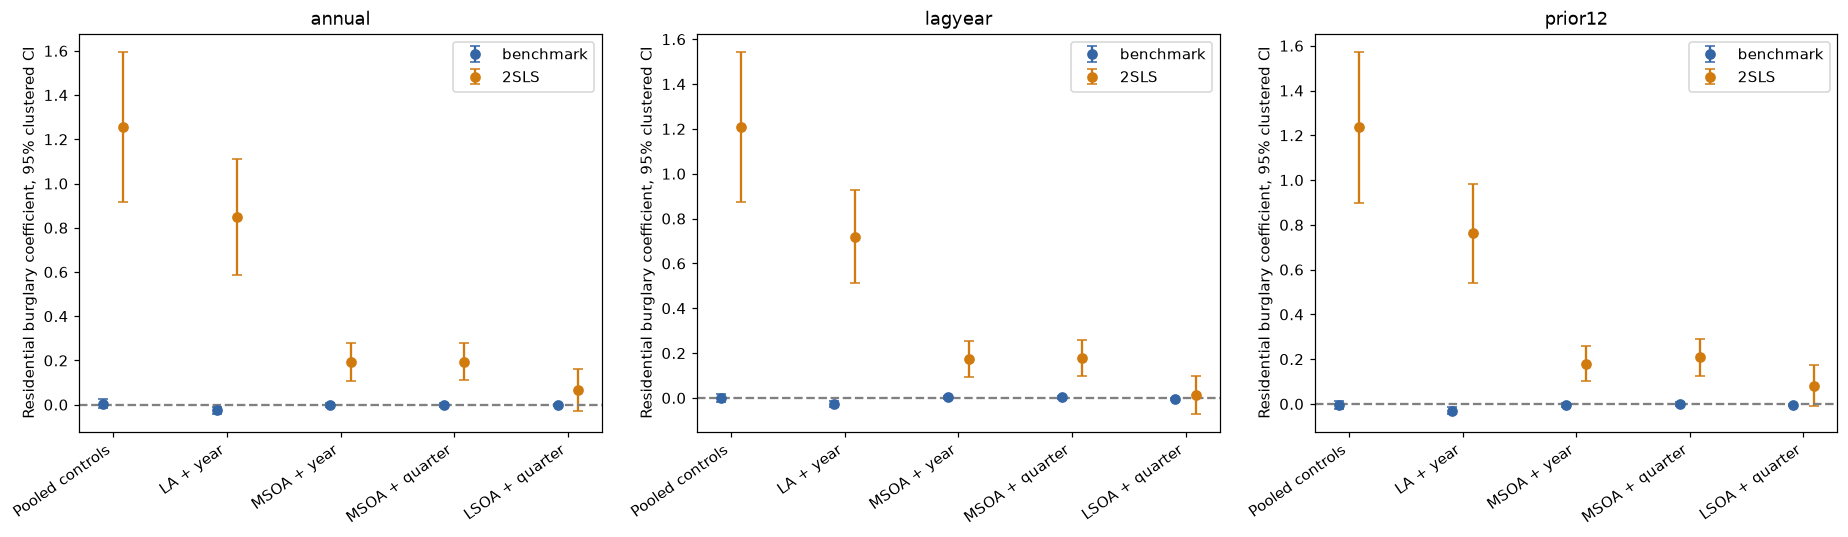

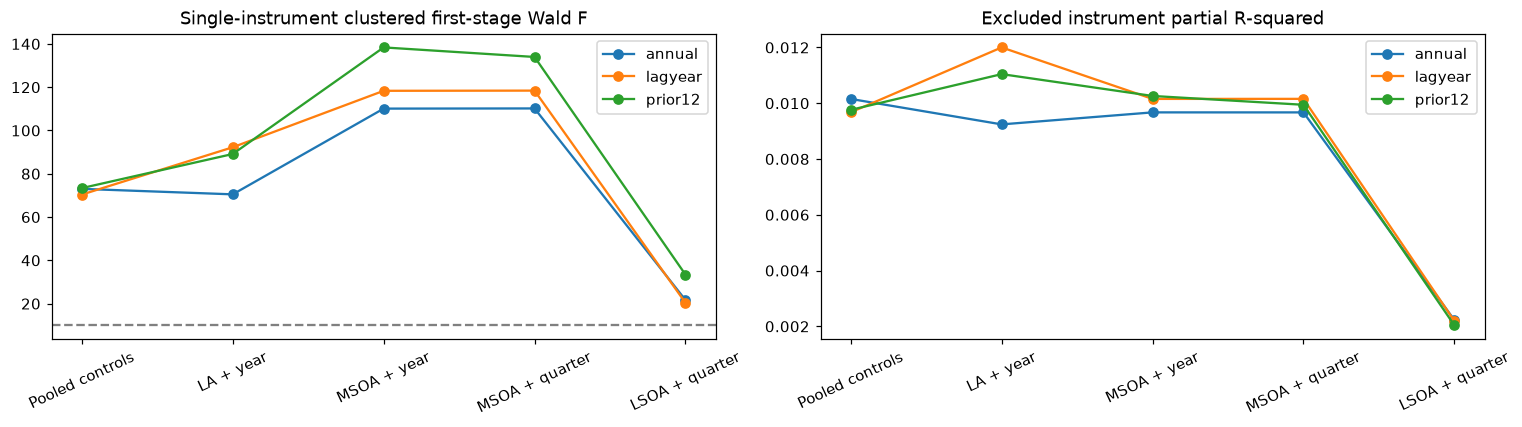

In [10]:
fig,axes=plt.subplots(1,3,figsize=(17,5))
labels=[name for name,_ in SPECS]
for ax,exposure in zip(axes,EXPOSURES):
    for method,offset,color in [('benchmark',-.09,'#3465a4'),('2SLS',.09,'#d17b0f')]:
        b=results.loc[results.exposure.eq(exposure)&(results.method.eq('2SLS') if method=='2SLS' else results.method.isin(['OLS','TWFE']))].set_index('specification').reindex(labels)
        ax.errorbar(np.arange(5)+offset,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',capsize=3,label=method,color=color)
    ax.axhline(0,color='grey',linestyle='--');ax.set_xticks(np.arange(5),labels,rotation=35,ha='right')
    ax.set_title(exposure);ax.set_ylabel('Residential burglary coefficient, 95% clustered CI');ax.legend()
fig.tight_layout();fig.savefig(OUT/'twfe_vs_iv.png',dpi=170,bbox_inches='tight');plt.show()
fig,axes=plt.subplots(1,2,figsize=(14,4))
for exposure in EXPOSURES:
    b=results.loc[results.exposure.eq(exposure)&results.method.eq('2SLS')].set_index('specification').reindex(labels)
    axes[0].plot(labels,b.first_stage_wald_F,marker='o',label=exposure)
    axes[1].plot(labels,b.partial_R2,marker='o',label=exposure)
for ax in axes:
    ax.tick_params(axis='x',rotation=25);ax.legend()
axes[0].axhline(10,color='grey',linestyle='--',label='Heuristic only')
axes[0].set_title('Single-instrument clustered first-stage Wald F')
axes[1].set_title('Excluded instrument partial R-squared')
fig.tight_layout();fig.savefig(OUT/'first_stage_strength.png',dpi=170,bbox_inches='tight');plt.show()


## 6. What additional data would improve identification?

The strongest direction is an externally determined change in policing/crime prevention with documented allocation rules, treatment dates and geography, whose housing-market channels can be defended. Collect programme assignment rules and pre-treatment outcomes, not just police presence. Allocation responding to local crime, regeneration or housing demand is itself endogenous.

A second research candidate is predicted local crime from pre-period local offence composition and offence-specific trends outside London. That needs harmonised national category/year counts excluding London, a pre-estimation-period local baseline, and an argument that the external shocks do not independently change local housing demand. Shift-share instruments are not automatically valid; a handful of shocks and shared macroeconomic drivers create difficult inference/exclusion problems. Neither this dataset nor this notebook supplies those external shocks.

Commercial floor-space changes were used in [Ihlanfeldt and Mayock](https://www.sciencedirect.com/science/article/pii/S0166046210000086), but changes in shops, jobs and amenities can directly affect London house prices, so that instrument should not be imported without defending exclusion. Pub distance, neighbouring prices and unemployment likewise have direct housing-market channels. A static LSOA-level candidate is absorbed by LSOA effects unless it has credible time variation.

This notebook is an exploratory extension using an available candidate. It does not establish a valid causal IV, and there is no requirement that 2SLS produce a negative coefficient.


## 7. Findings from this exploratory run

All 60 regressions use 338,295 sales across 4,645 LSOAs. First-stage strength changes substantially with geographical controls. The LSOA/year-quarter results are:

| Exposure | TWFE beta | 2SLS beta | 2SLS 95% clustered CI | First-stage Wald F |
|---|---:|---:|---|---:|
| Current calendar year | -0.00348 | +0.06636 | [-0.02818, +0.16091] | 21.68 |
| Previous calendar year | -0.00288 | +0.01323 | [-0.07045, +0.09690] | 20.40 |
| Prior twelve completed months | -0.00293 | +0.08098 | [-0.01097, +0.17294] | 33.42 |

All conventional 95% intervals above include zero; all three AR-style sets also include zero. These results do not establish a negative causal relationship. A first-stage F above ten does not prove that exclusion is valid, nor is ten a universal clustered weak-IV threshold. Larger positive estimates in coarser specifications may reflect an invalid instrument, different identifying variation or other model limitations; their sign alone cannot identify the reason.

The TWFE coefficients here target residential burglary, not the previous notebooks' total crime, violence or composite property crime. They are not interchangeable outcomes. Both the instrument and its exclusion concerns should be discussed explicitly in the report. This extension is suitable for exploring the mechanics and limitations of IV; it is not evidence that we have solved crime endogeneity.
